# Carga e inspección de datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    roc_curve, balanced_accuracy_score
)

import os
os.chdir("/Users/zrgv/OneDrive/Documentos/Cientifico de datos ebac/Modulo 21")

pd.set_option('display.max_columns', None)

df = pd.read_csv('recursos_humanos.csv')

print('Dimensiones:', df.shape)
display(df.head())
display(df.info())

Dimensiones: (14999, 10)


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   sales                  14999 non-null  object 
 9   salary                 14999 non-null  object 
dtypes: float64(2), int64(6), object(2)
memory usage: 1.1+ MB


None

### Comentario

La base contiene **14,999 registros y 10 variables**. La variable objetivo es `left`. Las variables categóricas identificadas son `sales` (departamento) y `salary` (categoría salarial).

In [2]:
print("Tipos de datos:")
display(df.dtypes)

print("\nValores faltantes por variable:")
display(df.isnull().sum().to_frame('faltantes'))

print("\nDuplicados:", df.duplicated().sum())

Tipos de datos:


satisfaction_level       float64
last_evaluation          float64
number_project             int64
average_montly_hours       int64
time_spend_company         int64
Work_accident              int64
left                       int64
promotion_last_5years      int64
sales                     object
salary                    object
dtype: object


Valores faltantes por variable:


,faltantes
satisfaction_level,0
last_evaluation,0
number_project,0
average_montly_hours,0
time_spend_company,0
Work_accident,0
left,0
promotion_last_5years,0
sales,0
salary,0



Duplicados: 3008


##  Recodificación de variables categóricas

Para que KNN pueda calcular distancias, todas las variables deben estar representadas numéricamente. Se utiliza `pd.get_dummies()` sobre `sales` y `salary`. Se conserva la variable objetivo `left` sin transformar.

In [3]:
X = df.drop(columns=['left'])
y = df['left']

X = pd.get_dummies(
    X,
    columns=['sales', 'salary'],
    drop_first=False,
    dtype=int
)

print("Variables después de la recodificación:")
display(X.head())
print("Número de variables predictoras:", X.shape[1])

Variables después de la recodificación:


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,sales_IT,sales_RandD,sales_accounting,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_high,salary_low,salary_medium
0,0.38,0.53,2,157,3,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0
1,0.80,0.86,5,262,6,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1
2,0.11,0.88,7,272,4,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1
3,0.72,0.87,5,223,5,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0
4,0.37,0.52,2,159,3,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0


Número de variables predictoras: 20


##  Análisis exploratorio: ¿la base está equilibrada?

Se analiza la distribución de la variable objetivo. Una base equilibrada tendría proporciones similares entre las clases. En este caso se calcula el número y porcentaje de empleados que permanecieron y que abandonaron.

,Categoría,Frecuencia,Porcentaje
0,No abandonó (0),11428,76.191746
1,Abandonó (1),3571,23.808254


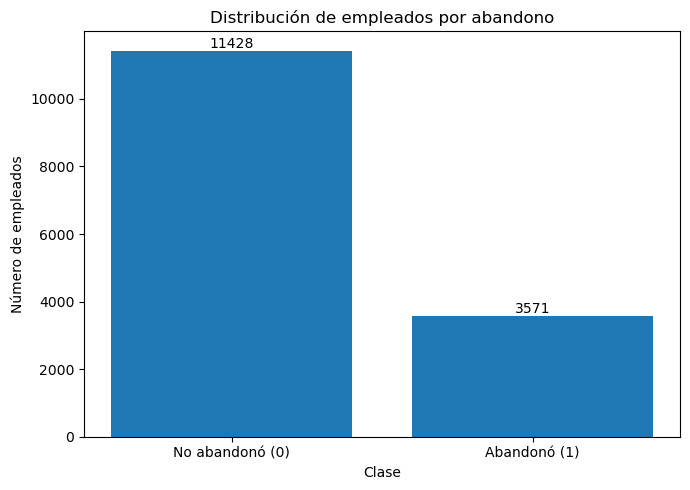

In [4]:
conteo = y.value_counts().sort_index()
porcentaje = y.value_counts(normalize=True).sort_index() * 100

balance = pd.DataFrame({
    'Categoría': ['No abandonó (0)', 'Abandonó (1)'],
    'Frecuencia': [conteo.get(0, 0), conteo.get(1, 0)],
    'Porcentaje': [porcentaje.get(0, 0), porcentaje.get(1, 0)]
})

display(balance)

plt.figure(figsize=(7,5))
bars = plt.bar(balance['Categoría'], balance['Frecuencia'])
plt.title('Distribución de empleados por abandono')
plt.xlabel('Clase')
plt.ylabel('Número de empleados')
plt.bar_label(bars, fmt='%d')
plt.tight_layout()
plt.show()

## División de datos y estandarización

Se separan los datos en **80% para entrenamiento y 20% para prueba**, utilizando `stratify=y` para conservar aproximadamente la misma proporción de clases en ambos conjuntos.

La estandarización es necesaria para KNN porque variables como horas mensuales, antigüedad y número de proyectos tienen escalas diferentes. El escalador se ajusta únicamente con el conjunto de entrenamiento para evitar fuga de información.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)
print("\nDistribución de y_train:")
display(y_train.value_counts(normalize=True).sort_index().mul(100).round(2))
print("\nDistribución de y_test:")
display(y_test.value_counts(normalize=True).sort_index().mul(100).round(2))


Entrenamiento: (11999, 20)
Prueba: (3000, 20)

Distribución de y_train:


left
0    76.19
1    23.81
Name: proportion, dtype: float64


Distribución de y_test:


left
0    76.2
1    23.8
Name: proportion, dtype: float64

## Evaluación de K = 1 a K = 20

Se entrena un clasificador KNN para cada valor de K. Se calculan:

- **Accuracy (exactitud):** proporción total de predicciones correctas.
- **Precision (precisión):** de los empleados predichos como desertores, cuántos realmente abandonaron.
- **Recall (sensibilidad):** de los empleados que realmente abandonaron, cuántos fueron detectados.
- **F1:** media armónica entre precision y recall.
- **AUC-ROC:** capacidad global de discriminación entre ambas clases.

Para un problema de Recursos Humanos, el **recall de la clase 1** es especialmente relevante porque representa la capacidad de detectar empleados que efectivamente abandonarán.

In [6]:
resultados = []

for k in range(1, 21):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)

    y_pred = knn.predict(X_test_scaled)
    y_prob = knn.predict_proba(X_test_scaled)[:, 1]

    resultados.append({
        'K': k,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'AUC-ROC': roc_auc_score(y_test, y_prob),
        'Balanced Accuracy': balanced_accuracy_score(y_test, y_pred)
    })

resultados_df = pd.DataFrame(resultados)
display(resultados_df.style.format({
    'Accuracy': '{:.4f}',
    'Precision': '{:.4f}',
    'Recall': '{:.4f}',
    'F1': '{:.4f}',
    'AUC-ROC': '{:.4f}',
    'Balanced Accuracy': '{:.4f}'
}))


,K,Accuracy,Precision,Recall,F1,AUC-ROC,Balanced Accuracy
0,1,0.9673,0.9085,0.9594,0.9332,0.9646,0.9646
1,2,0.9623,0.9275,0.9132,0.9203,0.9699,0.9454
2,3,0.9503,0.8722,0.9272,0.8988,0.9709,0.9424
3,4,0.9470,0.8959,0.8796,0.8876,0.9717,0.9238
4,5,0.9413,0.8635,0.8950,0.8790,0.9716,0.9254
5,6,0.9473,0.8927,0.8852,0.8889,0.9711,0.9260
6,7,0.9440,0.8771,0.8894,0.8832,0.9703,0.9252
7,8,0.9450,0.8872,0.8810,0.8840,0.9707,0.9230
8,9,0.9397,0.8646,0.8852,0.8747,0.9714,0.9209
9,10,0.9417,0.8790,0.8754,0.8772,0.9713,0.9189


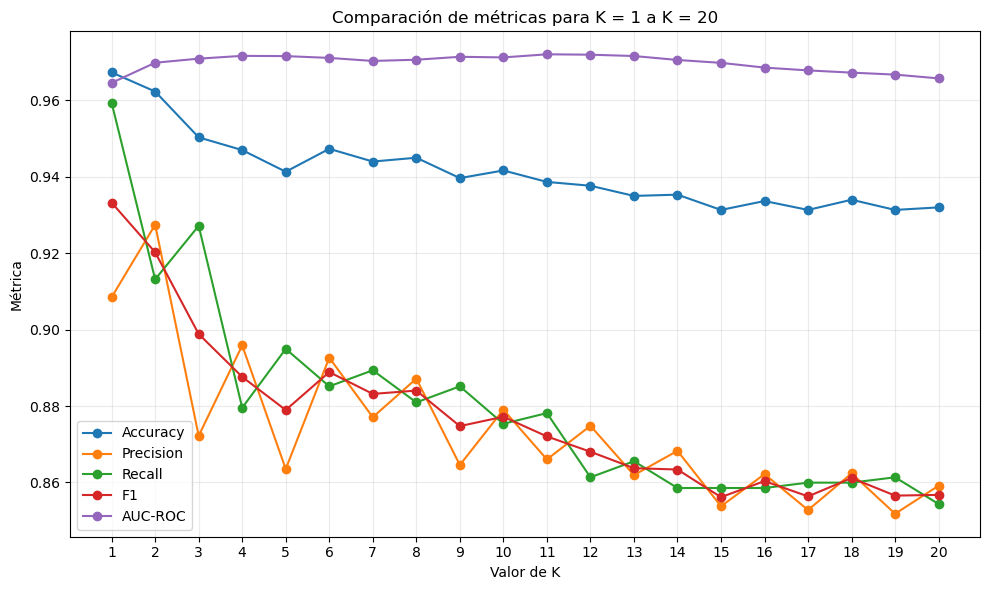

In [7]:
plt.figure(figsize=(10,6))
for col in ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC-ROC']:
    plt.plot(resultados_df['K'], resultados_df[col], marker='o', label=col)

plt.xticks(range(1,21))
plt.xlabel('Valor de K')
plt.ylabel('Métrica')
plt.title('Comparación de métricas para K = 1 a K = 20')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Matriz de confusión para K = 1

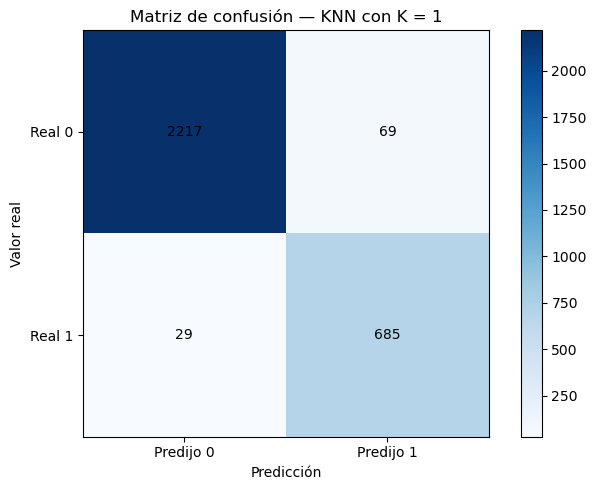

Matriz de confusión:
[[2217   69]
 [  29  685]]

Reporte de clasificación:
                 precision    recall  f1-score   support

No abandonó (0)       0.99      0.97      0.98      2286
   Abandonó (1)       0.91      0.96      0.93       714

       accuracy                           0.97      3000
      macro avg       0.95      0.96      0.96      3000
   weighted avg       0.97      0.97      0.97      3000



In [8]:
k_optimo = 1
modelo_knn = KNeighborsClassifier(n_neighbors=k_optimo)
modelo_knn.fit(X_train_scaled, y_train)

y_pred = modelo_knn.predict(X_test_scaled)
y_prob = modelo_knn.predict_proba(X_test_scaled)[:, 1]

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7,5))
plt.imshow(cm, interpolation='nearest', cmap='Blues')
plt.title('Matriz de confusión — KNN con K = 1')
plt.colorbar()
plt.xticks([0,1], ['Predijo 0', 'Predijo 1'])
plt.yticks([0,1], ['Real 0', 'Real 1'])
plt.xlabel('Predicción')
plt.ylabel('Valor real')
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j], ha='center', va='center')
plt.tight_layout()
plt.show()

print("Matriz de confusión:")
print(cm)
print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred, target_names=['No abandonó (0)', 'Abandonó (1)']))

## Curva ROC y AUC para K = 1

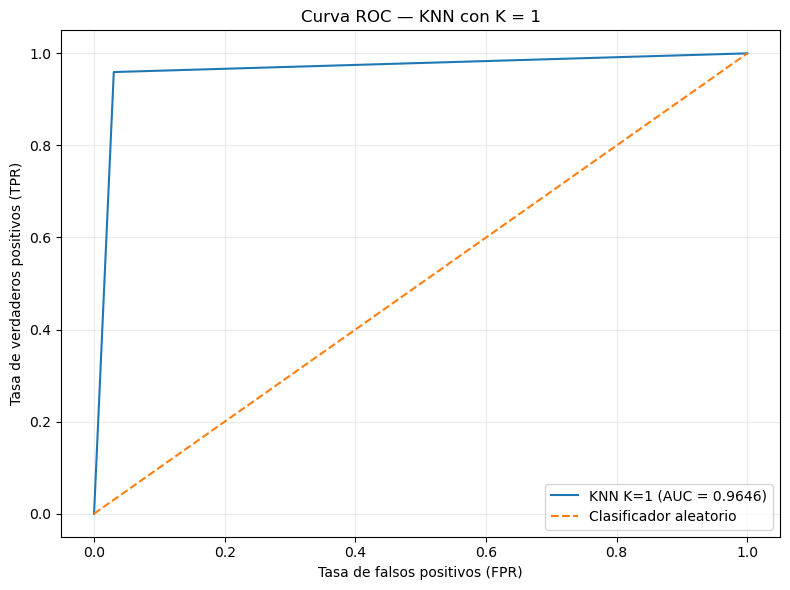

AUC-ROC = 0.9646


In [9]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f'KNN K={k_optimo} (AUC = {auc:.4f})')
plt.plot([0,1], [0,1], linestyle='--', label='Clasificador aleatorio')
plt.xlabel('Tasa de falsos positivos (FPR)')
plt.ylabel('Tasa de verdaderos positivos (TPR)')
plt.title('Curva ROC — KNN con K = 1')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(f"AUC-ROC = {auc:.4f}")
